Imports


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

Dataset Loading

In [2]:

path = "/content/adult income dataset.csv"

dataset = pd.read_csv(path)

for col in dataset.select_dtypes(include="object").columns:
    dataset[col] = dataset[col].str.strip()

print("Dataset loaded successfully.")
print("Shape:", dataset.shape)
display(dataset.head())

Dataset loaded successfully.
Shape: (48842, 15)


,Age,Workclass,Final Weight,Education,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Dataset information:")
dataset.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Age                        48842 non-null  int64 
 1   Workclass                  48842 non-null  object
 2   Final Weight               48842 non-null  int64 
 3   Education                  48842 non-null  object
 4   Education Number of Years  48842 non-null  int64 
 5   Marital-status             48842 non-null  object
 6   Occupation                 48842 non-null  object
 7   Relationship               48842 non-null  object
 8   Race                       48842 non-null  object
 9   Sex                        48842 non-null  object
 10  Capital-gain               48842 non-null  int64 
 11  Capital-loss               48842 non-null  int64 
 12  Hours-per-week             48842 non-null  int64 
 13  Native-country             48842 non-nul

In [4]:
print("Column names:")
for i, col in enumerate(dataset.columns, start=1):
    print(i, col)

Column names:
1 Age
2 Workclass
3 Final Weight
4 Education
5 Education Number of Years
6 Marital-status
7 Occupation
8 Relationship
9 Race
10 Sex
11 Capital-gain
12 Capital-loss
13 Hours-per-week
14 Native-country
15 target


In [5]:
target_col = "target"

print("Number of rows/data points:", dataset.shape[0])
print("Number of columns:", dataset.shape[1])
print("Number of input features:", dataset.shape[1] - 1)
print("Target column:", target_col)

print("\nTarget classes:")
display(dataset[target_col].value_counts())

Number of rows/data points: 48842
Number of columns: 15
Number of input features: 14
Target column: target

Target classes:


,count
target,
<=50K,37155
>50K,11687


In [6]:
numerical_features = dataset.drop(columns=[target_col]).select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = dataset.drop(columns=[target_col]).select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['Age', 'Final Weight', 'Education Number of Years', 'Capital-gain', 'Capital-loss', 'Hours-per-week']
Categorical features: ['Workclass', 'Education', 'Marital-status', 'Occupation', 'Relationship', 'Race', 'Sex', 'Native-country']
Number of numerical features: 6
Number of categorical features: 8


Exploratory Data Analysis (EDA)

In [7]:
display(dataset.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
Workclass,48842,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Final Weight,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
Education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education Number of Years,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
Marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,48842,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


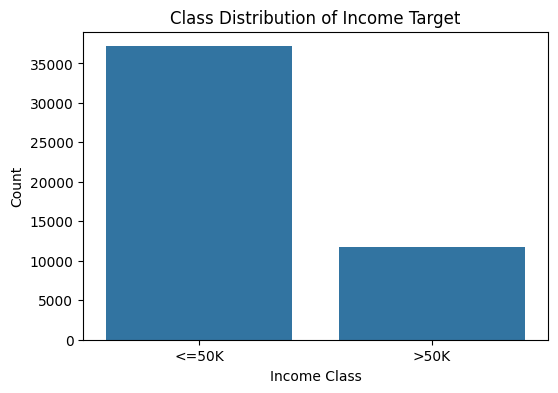

,Count,Percentage
target,,
<=50K,37155,76.07
>50K,11687,23.93


In [8]:
#target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x=target_col)
plt.title("Class Distribution of Income Target")
plt.xlabel("Income Class")
plt.ylabel("Count")
plt.show()

target_counts = dataset[target_col].value_counts()
target_percentages = dataset[target_col].value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})
display(imbalance_df)

Imbalanced Dataset Observation



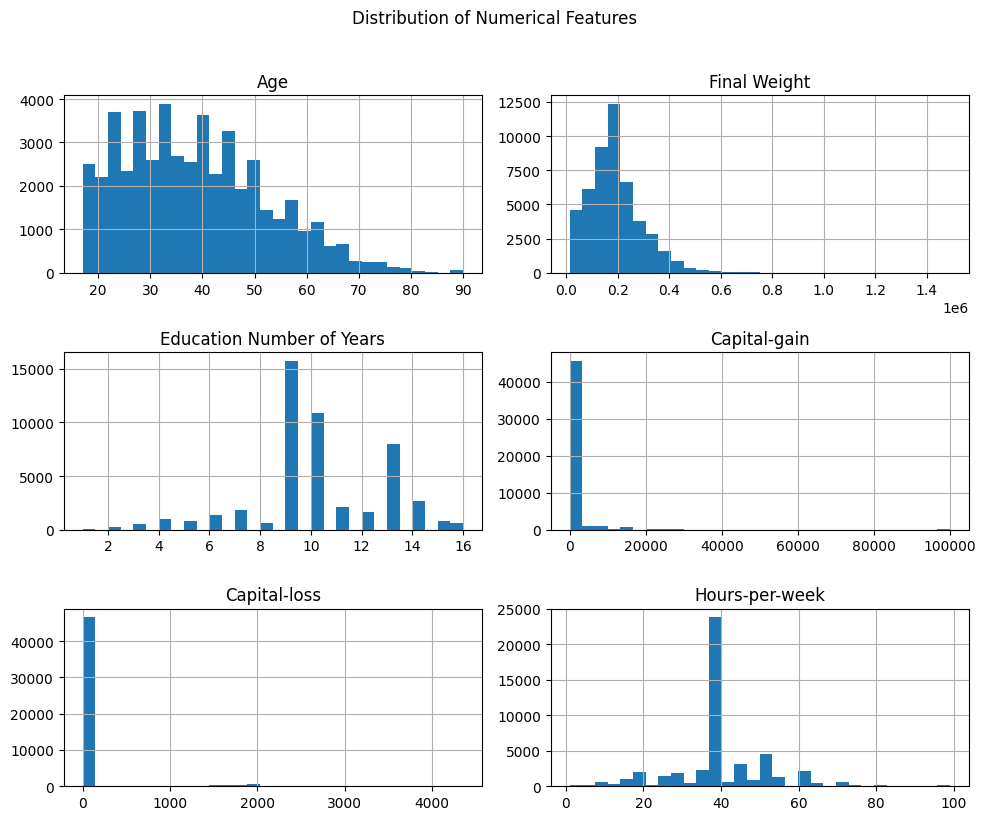

In [9]:
#Numeric feature distribution

dataset[numerical_features].hist(figsize=(10, 8), bins=30)
plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

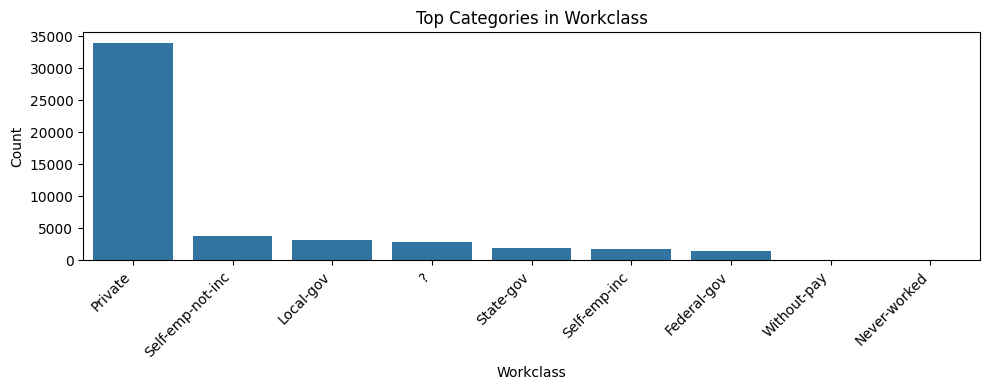

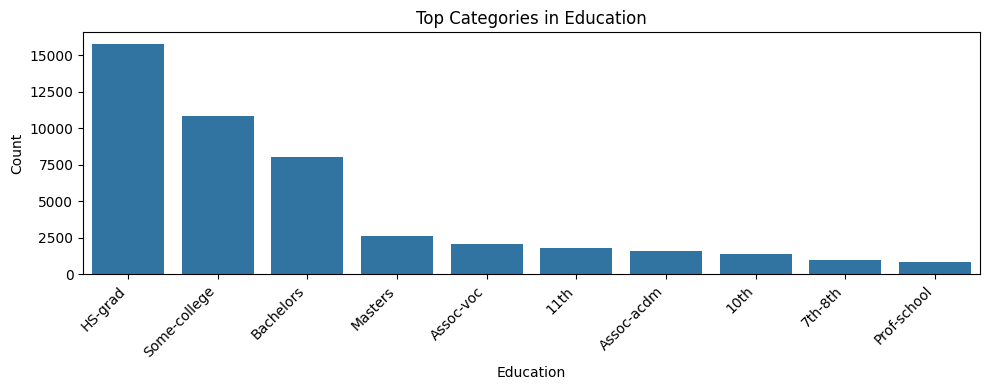

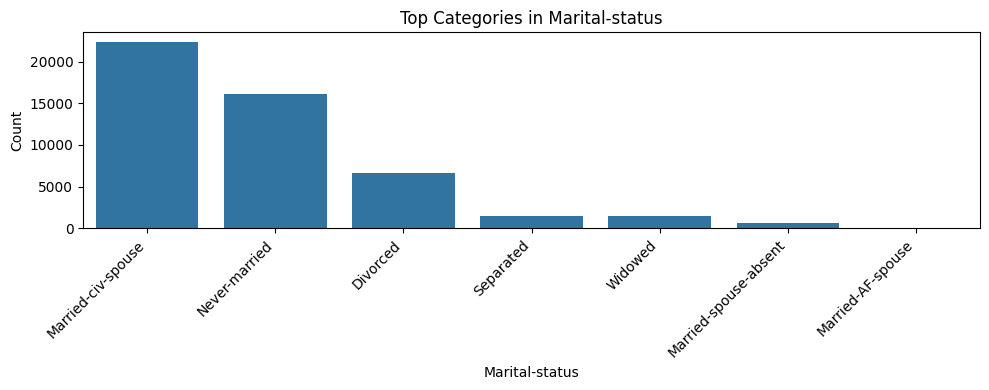

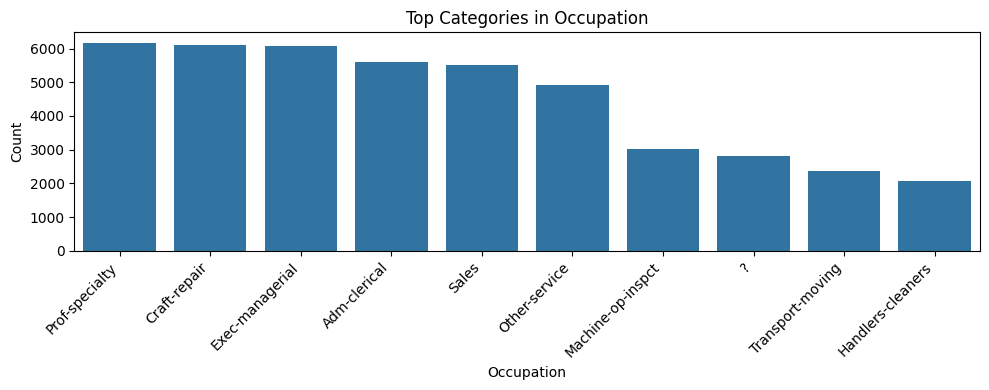

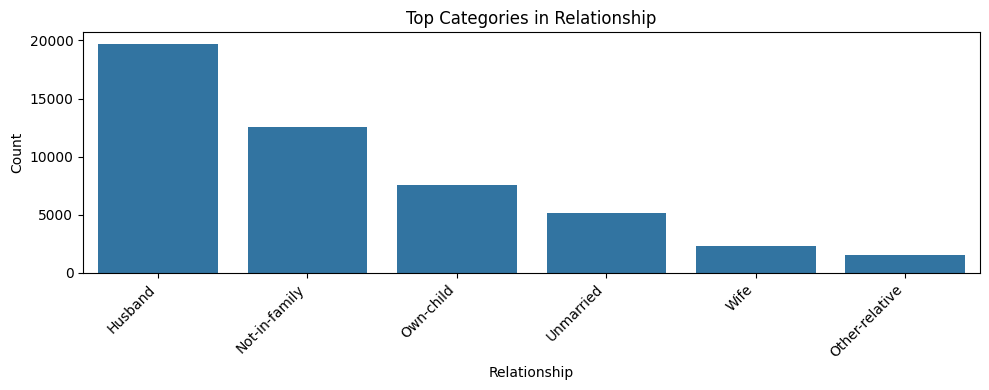

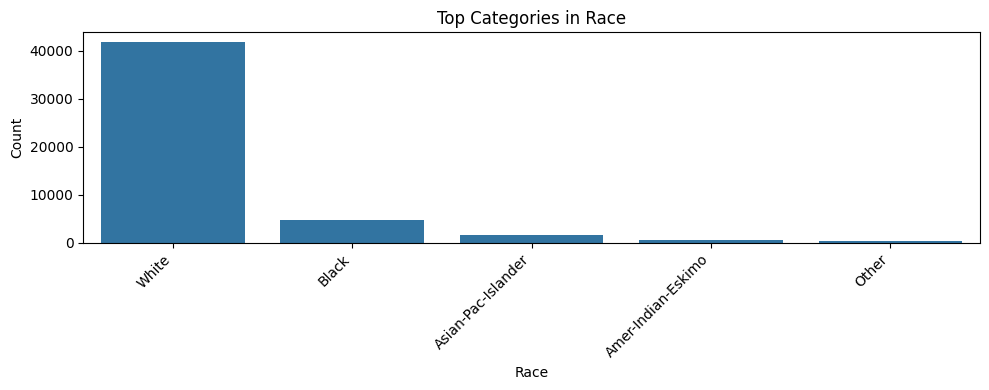

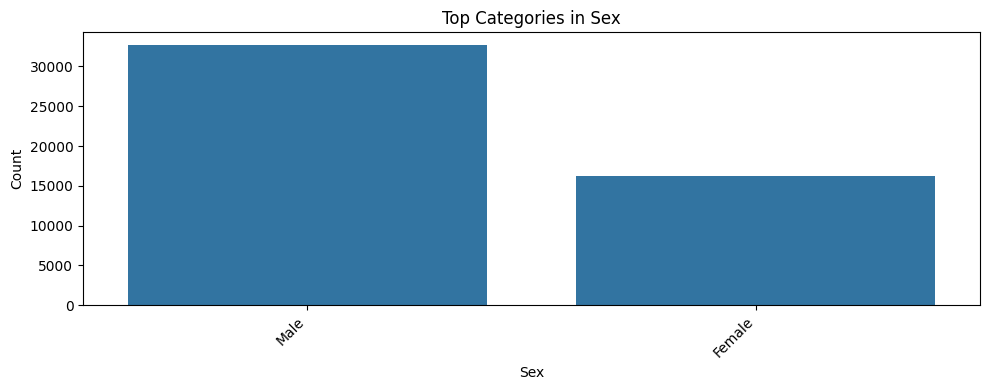

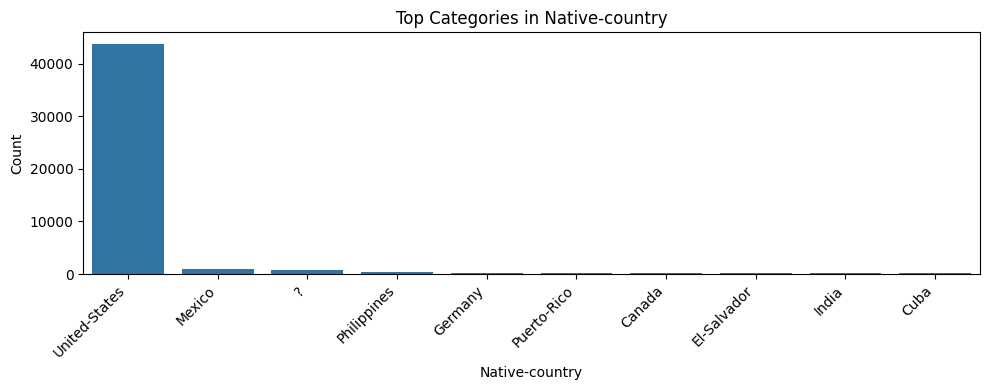

In [10]:
#feature distribution
for col in categorical_features:
    plt.figure(figsize=(10, 4))
    top_values = dataset[col].value_counts().head(10)
    sns.barplot(x=top_values.index, y=top_values.values)
    plt.title(f"Top Categories in {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

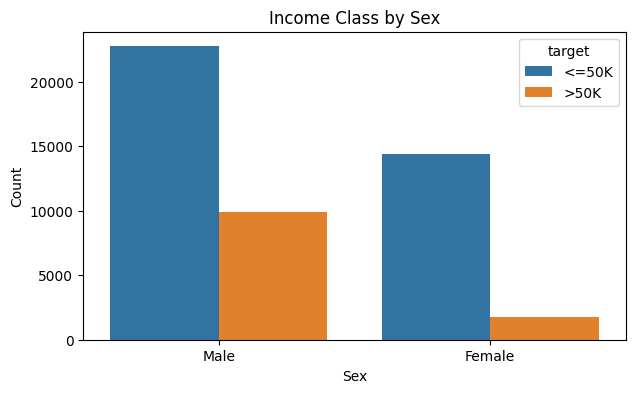

In [11]:
#sex and target
plt.figure(figsize=(7, 4))
sns.countplot(data=dataset, x="Sex", hue=target_col)
plt.title("Income Class by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

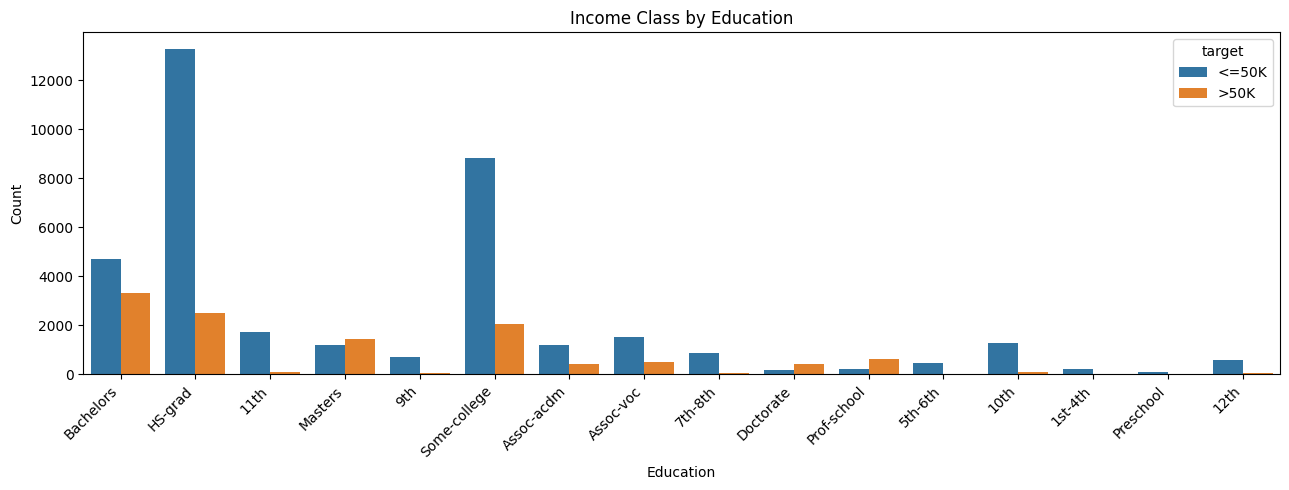

In [12]:
#education and target
plt.figure(figsize=(13, 5))
sns.countplot(data=dataset, x="Education", hue=target_col)
plt.title("Income Class by Education")
plt.xlabel("Education")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

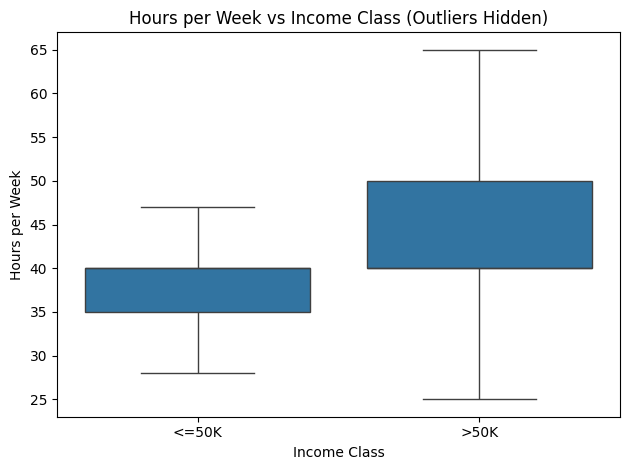

In [15]:
#hour-per-week and Income class


sns.boxplot(
    data=dataset,
    x=target_col,
    y="Hours-per-week",
    showfliers=False
)

plt.title("Hours per Week vs Income Class (Outliers Hidden)")
plt.xlabel("Income Class")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()

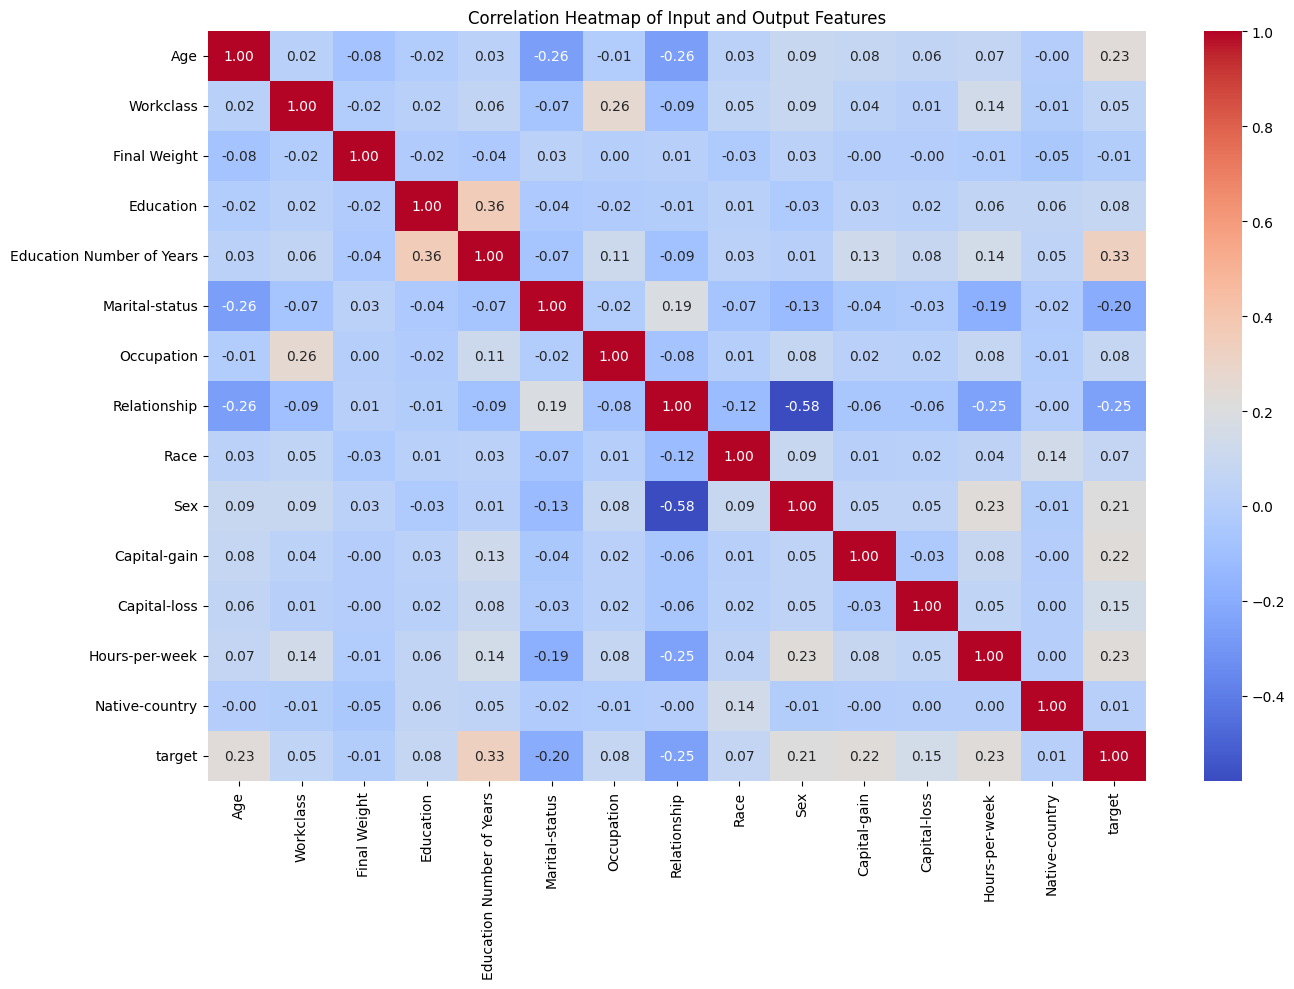

Correlation of features with target:


,target
target,1.000000
Education Number of Years,0.332613
Age,0.230369
Hours-per-week,0.227687
Capital-gain,0.223013
Sex,0.214628
Capital-loss,0.147554
Education,0.080091
Occupation,0.076722
Race,0.070934


In [16]:
corr_data = dataset.copy()
corr_data = corr_data.replace("?", np.nan)
corr_data[target_col] = corr_data[target_col].map({"<=50K": 0, ">50K": 1})


for col in categorical_features:
    corr_data[col] = corr_data[col].astype("category").cat.codes

corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Input and Output Features")
plt.tight_layout()
plt.show()

print("Correlation of features with target:")
display(corr_matrix[target_col].sort_values(ascending=False))

Dataset Pre-processing

In [17]:
dataset_clean = dataset.copy()

print("Missing values before replacing '?':")
display(dataset_clean.isnull().sum())

question_mark_counts = (dataset_clean == "?").sum()
print("\nQuestion mark counts:")
display(question_mark_counts[question_mark_counts > 0])

dataset_clean = dataset_clean.replace(r"^\s*\?\s*$", np.nan, regex=True)

print("\nMissing values after replacing '?' with nan:")
display(dataset_clean.isnull().sum()[dataset_clean.isnull().sum() > 0])

Missing values before replacing '?':


,0
Age,0
Workclass,0
Final Weight,0
Education,0
Education Number of Years,0
Marital-status,0
Occupation,0
Relationship,0
Race,0
Sex,0



Question mark counts:


,0
Workclass,2799
Occupation,2809
Native-country,857



Missing values after replacing '?' with nan:


,0
Workclass,2799
Occupation,2809
Native-country,857


Categorical values



Feature scaling



In [18]:
#seperating input data between feature and target

X= dataset_clean.drop(columns=[target_col])
y= dataset_clean[target_col].map({"<=50K": 0, ">50K": 1})



print("input shape:", X.shape)
print("target shape:", y.shape)
display(y.value_counts().rename(index={0: "<=50K", 1: ">50K"}))

input shape: (48842, 14)
target shape: (48842,)


,count
target,
<=50K,37155
>50K,11687


In [19]:

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print('Recalculate feature types after cleaning')
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Recalculate feature types after cleaning
Numerical features: ['Age', 'Final Weight', 'Education Number of Years', 'Capital-gain', 'Capital-loss', 'Hours-per-week']
Categorical features: ['Workclass', 'Education', 'Marital-status', 'Occupation', 'Relationship', 'Race', 'Sex', 'Native-country']


In [20]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder())
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor

print("the preprocessing is ready now.")

the preprocessing is ready now.


Dataset Splitting

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename(index={0: "<=50K", 1: ">50K"}) * 100)

print("Testing target distribution:")
display(y_test.value_counts(normalize=True).rename(index={0: "<=50K", 1: ">50K"}) * 100)

X_train: (39073, 14)
X_test: (9769, 14)
y_train: (39073,)
y_test: (9769,)
Training target distribution:


,proportion
target,
<=50K,76.072992
>50K,23.927008


Testing target distribution:


,proportion
target,
<=50K,76.067151
>50K,23.932849


Model Training and Testing


In [22]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),
    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=60,
        early_stopping=True,
        random_state=42,
        learning_rate_init=0.001
    )
}

trained_models = {}
model_outputs = {}
results = []

for model_name, model in models.items():
    print(f"Training {model_name}...")

    pipe = Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    auc = roc_auc_score(y_test, y_proba)

    trained_models[model_name] = pipe
    model_outputs[model_name] = {
        "y_pred": y_pred,
        "y_proba": y_proba
    }

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision_weighted": prec,
        "Recall_weighted": rec,
        "F1_weighted": f1,
        "AUC": auc
    })

    print(f"{model_name} completed. Accuracy: {acc:.4f}, AUC: {auc:.4f}")

results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
display(results_df)

Training Logistic Regression...
Logistic Regression completed. Accuracy: 0.8068, AUC: 0.9040
Training KNN...
KNN completed. Accuracy: 0.8299, AUC: 0.8601
Training Neural Network...
Neural Network completed. Accuracy: 0.8600, AUC: 0.9135


,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,AUC
2,Neural Network,0.859965,0.855127,0.859965,0.856424,0.913492
1,KNN,0.829870,0.824704,0.829870,0.826707,0.860148
0,Logistic Regression,0.806838,0.849961,0.806838,0.817659,0.903980


Results of All Supervised Models

Logistic Regression
Classification Report:
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      7431
        >50K       0.57      0.84      0.67      2338

    accuracy                           0.81      9769
   macro avg       0.75      0.82      0.77      9769
weighted avg       0.85      0.81      0.82      9769



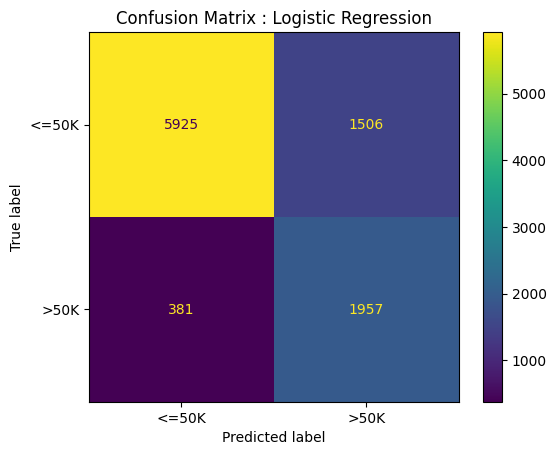

KNN
Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.90      0.89      7431
        >50K       0.66      0.59      0.63      2338

    accuracy                           0.83      9769
   macro avg       0.77      0.75      0.76      9769
weighted avg       0.82      0.83      0.83      9769



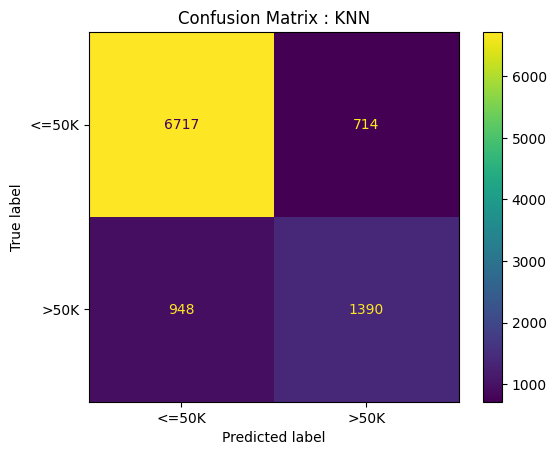

Neural Network
Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7431
        >50K       0.74      0.64      0.69      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.78      0.80      9769
weighted avg       0.86      0.86      0.86      9769



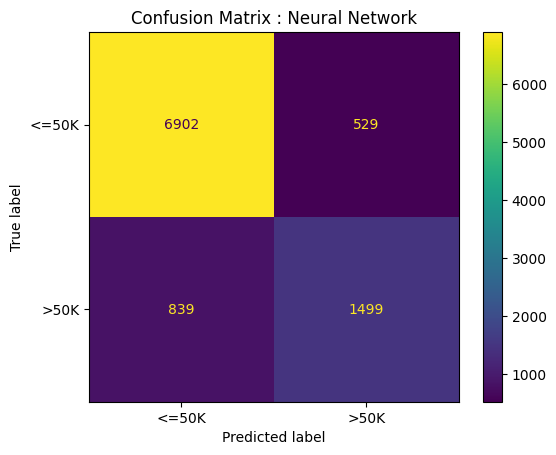

In [23]:
class_names = ["<=50K", ">50K"]

for model_name in models.keys():
    print("=" * 50)
    print(model_name)
    print("=" * 50)

    y_pred = model_outputs[model_name]["y_pred"]

    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix : {model_name}")
    plt.show()

### AUC Score and ROC Curve for Each Model

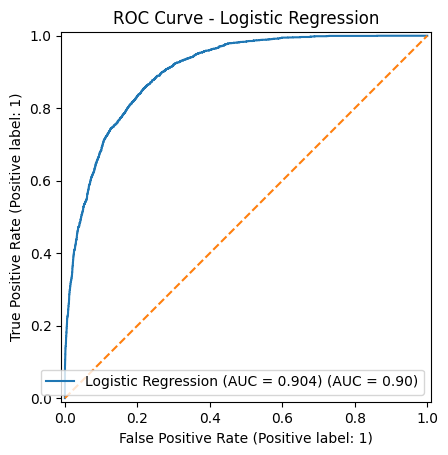

the model Logistic Regression has  AUC score: 0.9040


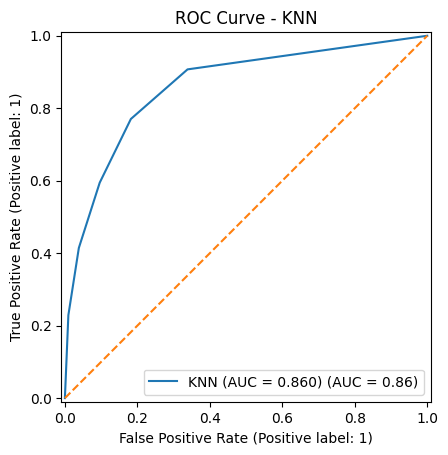

the model KNN has  AUC score: 0.8601


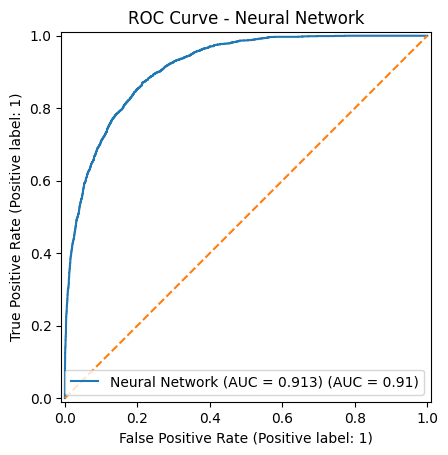

the model Neural Network has  AUC score: 0.9135


In [ ]:
for model_name in models.keys():
    y_proba = model_outputs[model_name]["y_proba"]
    auc_score = roc_auc_score(y_test, y_proba)


    RocCurveDisplay.from_predictions(
        y_test,
        y_proba,
        name=f"{model_name} (AUC = {auc_score:.3f})"
    )
    plt.title(f"ROC Curve - {model_name}")
    plt.plot([0,1], [0,1], linestyle="--")
    plt.show()

    print(f"the model {model_name} has  AUC score: {auc_score:.4f}")

All Model Summary

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,AUC
2,Neural Network,0.859965,0.855127,0.859965,0.856424,0.913492
1,KNN,0.829870,0.824704,0.829870,0.826707,0.860148
0,Logistic Regression,0.806838,0.849961,0.806838,0.817659,0.903980


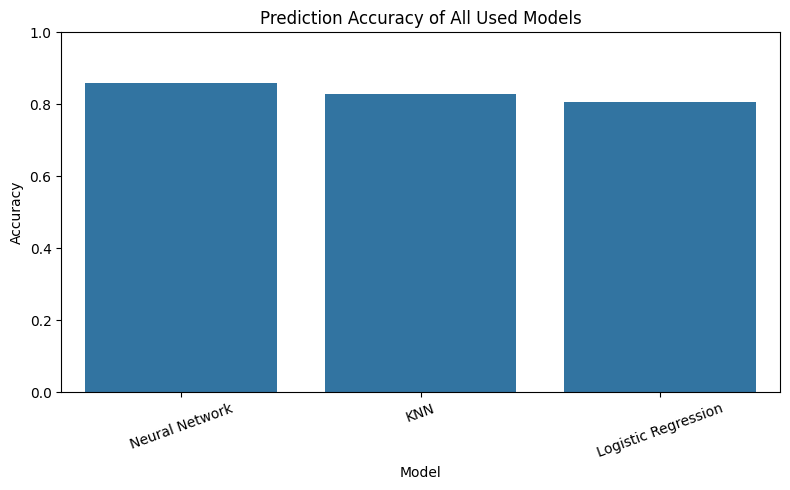

In [24]:
display(results_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Prediction Accuracy of All Used Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

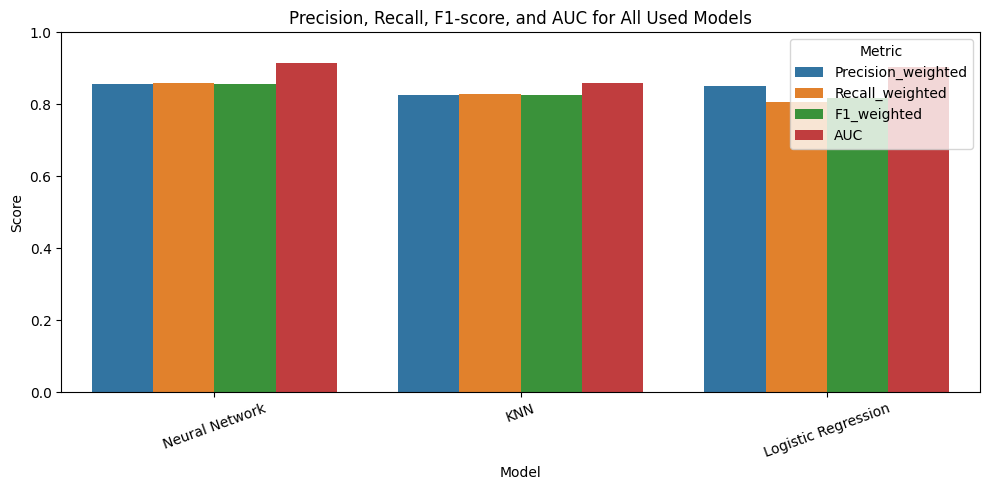

In [25]:
metrics_to_plot = ["Precision_weighted", "Recall_weighted", "F1_weighted", "AUC"]
metrics_df = results_df.melt(id_vars="Model", value_vars=metrics_to_plot,
                             var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x="Model", y="Score", hue="Metric")
plt.title("Precision, Recall, F1-score, and AUC for All Used Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Neural Network Loss Curve


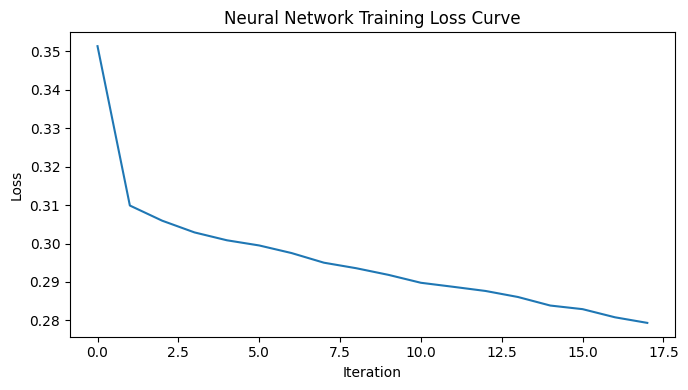

In [26]:
nn_model = trained_models["Neural Network"].named_steps["model"]

plt.figure(figsize=(7, 4))
plt.plot(nn_model.loss_curve_)
plt.title("Neural Network Training Loss Curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

KMeans Clustering(Unsupervised Learning)


In [27]:
X_cluster_ready = make_preprocessor().fit_transform(X) #the target is not included since this is unsupervised

print("Shape after preprocessing for KMeans:", X_cluster_ready.shape)

Shape after preprocessing for KMeans: (48842, 105)


In [28]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_cluster_ready)

cluster_df = pd.DataFrame({
    "Cluster": clusters,
    "Actual Income": dataset_clean[target_col].values
})

print("Cluster counts:")
display(cluster_df["Cluster"].value_counts().sort_index())

Cluster counts:


,count
Cluster,
0,23322
1,25520


In [29]:
cluster_income_table = pd.crosstab(
    cluster_df["Cluster"],
    cluster_df["Actual Income"],
    normalize="index"
) * 100

print("Percentage of actual income classes inside each cluster:")
display(cluster_income_table.round(2))

Percentage of actual income classes inside each cluster:


Actual Income,<=50K,>50K
Cluster,,
0,95.32,4.68
1,58.48,41.52


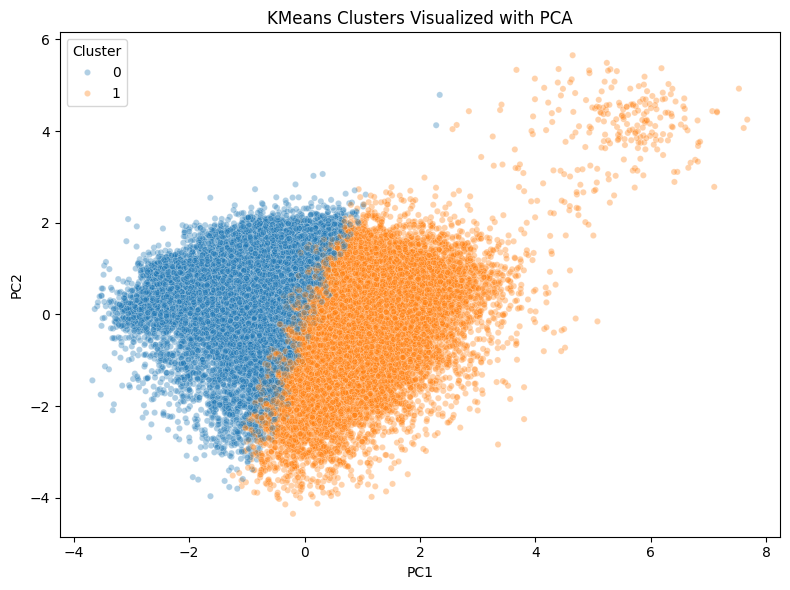

In [30]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster_ready)

cluster_plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": clusters,
    "Actual Income": dataset_clean[target_col].values
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=cluster_plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    alpha=0.35,
    s=20
)
plt.title("KMeans Clusters Visualized with PCA")
plt.tight_layout()
plt.show()

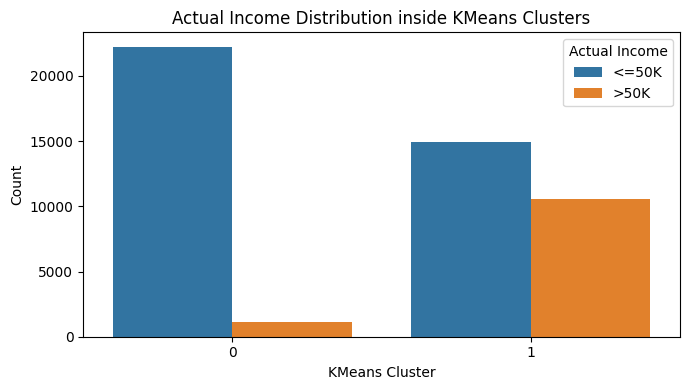

In [31]:
plt.figure(figsize=(7, 4))
sns.countplot(data=cluster_plot_df, x="Cluster", hue="Actual Income")
plt.title("Actual Income Distribution inside KMeans Clusters")
plt.xlabel("KMeans Cluster")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [32]:
!git --version

git version 2.43.0


In [33]:
!git clone https://github.com/TajrianTuba/CSE422-Project.git

Cloning into 'CSE422-Project'...


In [34]:
%cd CSE422-Project

/content/CSE422-Project


In [35]:
!ls /content

'adult income dataset.csv'   CSE422-Project   sample_data


In [36]:
!ls /content/*.ipynb

ls: cannot access '/content/*.ipynb': No such file or directory
